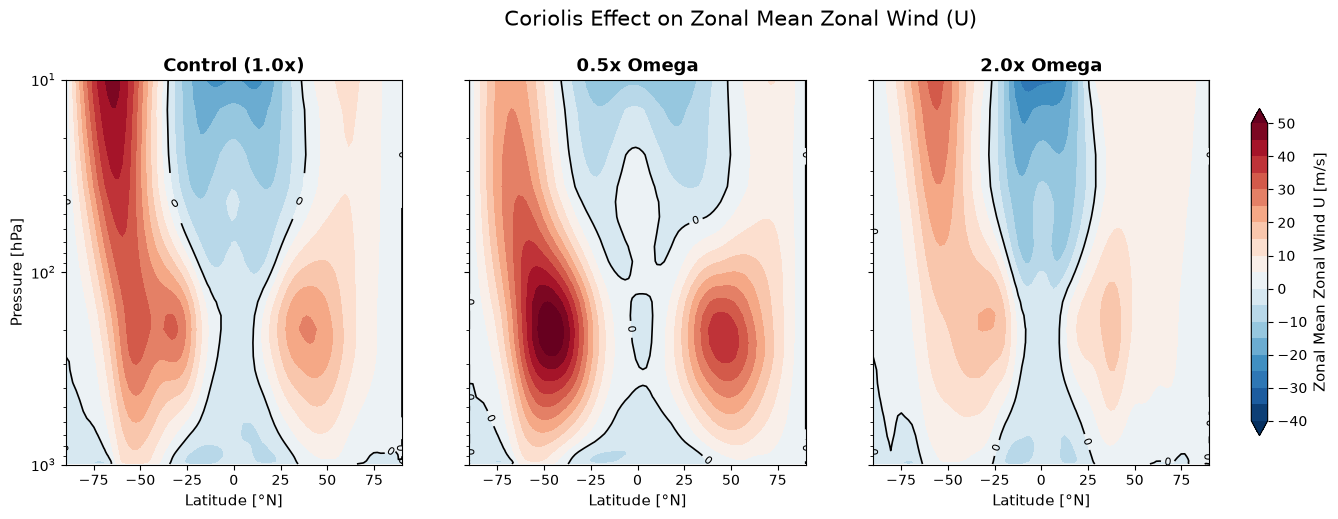

In [ ]:
import glob
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

run_base = "/orcd/scratch/orcd/013/dmyeong/cesm2_course/scratch/archive"

ctl_files  = sorted(glob.glob(f"{run_base}/dmyeong.f2000.control/atm/hist/*.cam.h0.*.nc"))
exp1_files = sorted(glob.glob(f"{run_base}/dmyeong.exp_omega_0p5/atm/hist/*.cam.h0.*.nc"))
exp2_files = sorted(glob.glob(f"{run_base}/dmyeong.exp_omega_2p0/atm/hist/*.cam.h0.*.nc"))

# include spinup months to avoid initial transient effects in the analysis
spinup_months = 12
cases_data = {}

if len(ctl_files) > 0:
    h1 = xr.open_mfdataset(ctl_files, combine="by_coords", data_vars="minimal")
    cases_data['Control (1.0x)'] = h1['U'].isel(time=slice(spinup_months, None)).mean(dim=['time', 'lon'])

if len(exp1_files) > 0:
    h2 = xr.open_mfdataset(exp1_files, combine="by_coords", data_vars="minimal")
    cases_data['0.5x Omega'] = h2['U'].isel(time=slice(spinup_months, None)).mean(dim=['time', 'lon'])

if len(exp2_files) > 0:
    h3 = xr.open_mfdataset(exp2_files, combine="by_coords", data_vars="minimal")
    cases_data['2.0x Omega'] = h3['U'].isel(time=slice(spinup_months, None)).mean(dim=['time', 'lon'])


# plotting of zonal mean zonal wind (U) for each case (not included in the report)
num_cases = len(cases_data)

if num_cases > 0:
    fig, axes = plt.subplots(1, num_cases, figsize=(6 * num_cases, 5), sharey=True)
    if num_cases == 1:
        axes = [axes]
        
    levels = np.arange(-40, 55, 5)

    for ax, (title, u_data) in zip(axes, cases_data.items()):
        lat = u_data['lat']
        lev = u_data['lev']

        cf = ax.contourf(lat, lev, u_data, levels=levels, cmap='RdBu_r', extend='both')        
        cs = ax.contour(lat, lev, u_data, levels=[0], colors='black', linewidths=1.2)
        ax.clabel(cs, inline=True, fontsize=8, fmt='%d')
        
        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel('Latitude [°N]', fontsize=11)
        ax.set_xlim(-90, 90)
        
        
        ax.set_yscale('log')
        ax.set_ylim(1000, 10)

    axes[0].set_ylabel('Pressure [hPa]', fontsize=11)

    cbar = fig.colorbar(cf, ax=list(axes), orientation='vertical', shrink=0.85, pad=0.03)
    cbar.set_label('Zonal Mean Zonal Wind U [m/s]', fontsize=11)

    plt.suptitle('Coriolis Effect on Zonal Mean Zonal Wind (U)', fontsize=15, y=1.02)
    plt.show()
else:
    print("No data found")

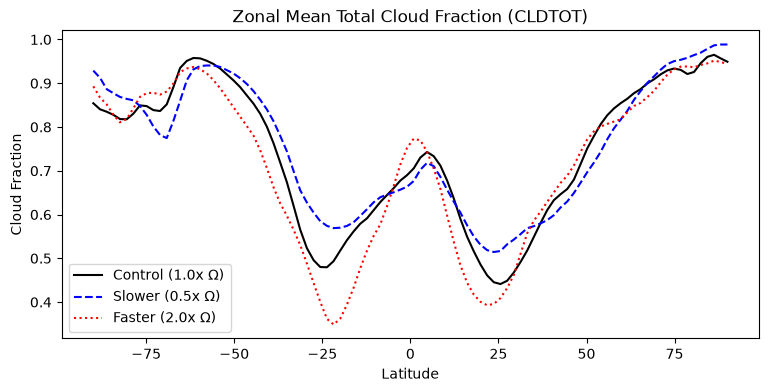

In [21]:
# plotting of zonal mean total cloud fraction (CLDTOT) for each case

# include spinup months to avoid initial transient effects in the analysis
spinup_months = 12

cld_ctl = h1['CLDTOT'].isel(time=slice(spinup_months, None)).mean(dim=['time','lon'])
cld_0p5 = h2['CLDTOT'].isel(time=slice(spinup_months, None)).mean(dim=['time', 'lon'])
cld_2p0 = h3['CLDTOT'].isel(time=slice(spinup_months, None)).mean(dim=['time', 'lon'])

plt.figure(figsize=(9, 4))
plt.plot(h1['lat'], cld_ctl, 'k-', label='Control (1.0x $\Omega$)')
plt.plot(h2['lat'], cld_0p5, 'b--', label='Slower (0.5x $\Omega$)')
plt.plot(h3['lat'], cld_2p0, 'r:', label='Faster (2.0x $\Omega$)')
plt.xlabel('Latitude')
plt.ylabel('Cloud Fraction')
plt.title('Zonal Mean Total Cloud Fraction (CLDTOT)')
plt.legend()
plt.show()


In [36]:
# calculation of global albedo for each case


fsnt_ctl_da = h1['FSNTOA']
fsnt_0p5_da = h2['FSNTOA']
fsnt_2p0_da = h3['FSNTOA']

# include spinup months to avoid initial transient effects in the analysis
spinup_months = 12

solin_ctl = h1['SOLIN'].isel(time=slice(spinup_months, None)).mean(dim='time').where(h1['SOLIN'].mean(dim='time') > 0)
solin_0p5 = h2['SOLIN'].isel(time=slice(spinup_months, None)).mean(dim='time').where(h2['SOLIN'].mean(dim='time') > 0)
solin_2p0 = h3['SOLIN'].isel(time=slice(spinup_months, None)).mean(dim='time').where(h3['SOLIN'].mean(dim='time') > 0)


fsnt_ctl = fsnt_ctl_da.isel(time=slice(spinup_months, None)).mean(dim='time')
fsnt_0p5 = fsnt_0p5_da.isel(time=slice(spinup_months, None)).mean(dim='time')
fsnt_2p0 = fsnt_2p0_da.isel(time=slice(spinup_months, None)).mean(dim='time')

def area_mean(da):
    weights = np.cos(np.deg2rad(da['lat']))
    weights.name = "weights"
    weighted_da = da.weighted(weights)
    dims_to_mean = [dim for dim in ['lat', 'lon'] if dim in da.dims]
    return weighted_da.mean(dim=dims_to_mean)

reflected_ctl = area_mean(solin_ctl - fsnt_ctl)
incoming_ctl = area_mean(solin_ctl)
albedo_ctl    = reflected_ctl / incoming_ctl

reflected_0p5 = area_mean(solin_0p5 - fsnt_0p5)
incoming_0p5  = area_mean(solin_0p5)
albedo_0p5    = reflected_0p5 / incoming_0p5

reflected_2p0 = area_mean(solin_2p0 - fsnt_2p0)
incoming_2p0  = area_mean(solin_2p0)
albedo_2p0    = reflected_2p0 / incoming_2p0

print(f"Global Albedo (1.0x): {albedo_ctl.values.item():.3f}")
print(f"Global Albedo (0.5x): {albedo_0p5.values.item():.3f}")
print(f"Global Albedo (2.0x): {albedo_2p0.values.item():.3f}")

Global Albedo (1.0x): 0.294
Global Albedo (0.5x): 0.314
Global Albedo (2.0x): 0.263


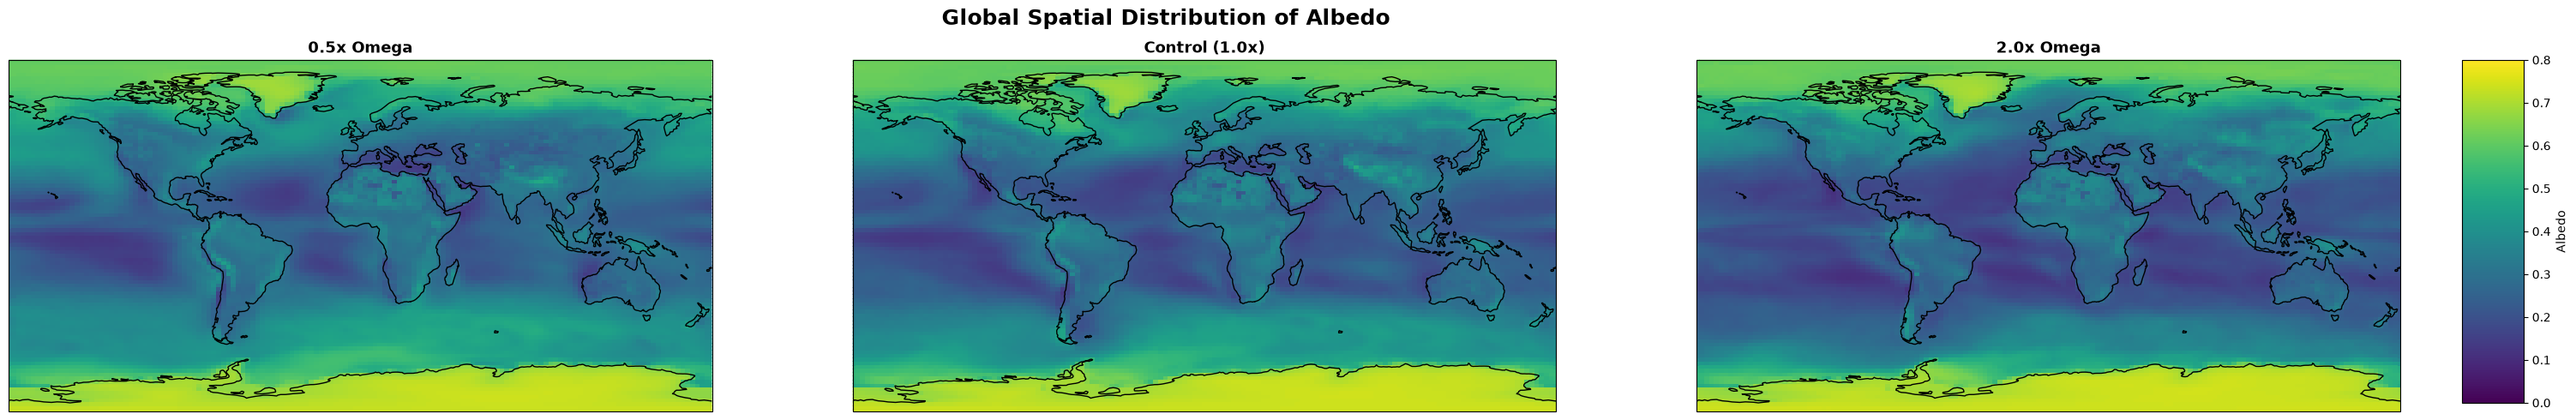

In [38]:
import cartopy.crs as ccrs

#plotting of global spatial distribution of albedo for each case

# include spinup months to avoid initial transient effects in the analysis
spinup_months = 12

solin_ctl = (
    h1['SOLIN']
    .isel(time=slice(spinup_months, None))
    .mean(dim='time')
    .where(lambda x: x > 0)
)
solin_0p5 = (
    h2['SOLIN']
    .isel(time=slice(spinup_months, None))
    .mean(dim='time')
    .where(lambda x: x > 0)
)
solin_2p0 = (
    h3['SOLIN']
    .isel(time=slice(spinup_months, None))
    .mean(dim='time')
    .where(lambda x: x > 0)
)

fsnt_ctl_da = h1['FSNTOA'].isel(time=slice(spinup_months, None))
fsnt_0p5_da = h2['FSNTOA'].isel(time=slice(spinup_months, None))
fsnt_2p0_da = h3['FSNTOA'].isel(time=slice(spinup_months, None))

fsnt_ctl = fsnt_ctl_da.mean(dim='time')
fsnt_0p5 = fsnt_0p5_da.mean(dim='time')
fsnt_2p0 = fsnt_2p0_da.mean(dim='time')


def calc_grid_albedo(solin, fsnt):
  reflected = solin - fsnt
  return (reflected / solin).where(solin > 0)


albedo_2d_ctl = calc_grid_albedo(solin_ctl, fsnt_ctl)
albedo_2d_0p5 = calc_grid_albedo(solin_0p5, fsnt_0p5)
albedo_2d_2p0 = calc_grid_albedo(solin_2p0, fsnt_2p0)

glob_albedo_data = {}


glob_albedo_data['0.5x Omega'] = calc_grid_albedo(solin_0p5, fsnt_0p5)
glob_albedo_data['Control (1.0x)'] = calc_grid_albedo(solin_ctl, fsnt_ctl)
glob_albedo_data['2.0x Omega'] = calc_grid_albedo(solin_2p0, fsnt_2p0)


num_cases = len(glob_albedo_data)

if num_cases > 0:
    fig, axes = plt.subplots(1, num_cases, figsize=(12 * num_cases, 10), sharey=True, subplot_kw={'projection': ccrs.PlateCarree()})
    if num_cases == 1:
        axes = [axes]

    for ax, (title, albedo_data) in zip(axes, glob_albedo_data.items()):
        im = albedo_data.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap='viridis',
            add_colorbar=False,
            vmin=0.0,
            vmax=0.8
        )
        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.coastlines()
        ax.set_global()

    cbar_ax = fig.add_axes([0.92, 0.3, 0.02, 0.4])  # [left, bottom, width, height]
    fig.colorbar(im, cax=cbar_ax, label='Albedo')
    plt.suptitle('Global Spatial Distribution of Albedo', fontsize=18, y=0.76, fontweight='bold')
    plt.show()

else:
    print("No data found")

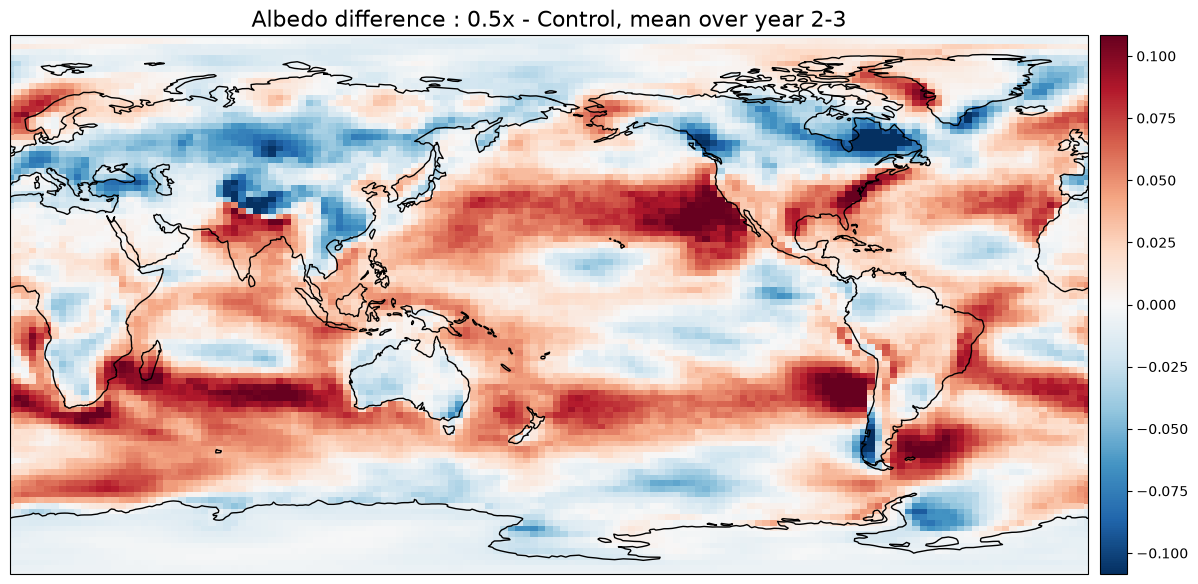

In [24]:
# plotting the difference map between the 0.5x Omega case and the control case
albedo_0p5_diff = albedo_2d_0p5 - albedo_2d_ctl
lim = float(np.abs(albedo_0p5_diff).quantile(0.99))

fig = plt.figure(figsize=(15, 7))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree(central_longitude=180))
img = ax.pcolormesh(albedo_0p5_diff.lon, albedo_0p5_diff.lat, albedo_0p5_diff, cmap="RdBu_r",
                    vmin=-lim, vmax=lim, transform=ccrs.PlateCarree())
ax.coastlines()
plt.colorbar(img, orientation="vertical", fraction=0.0242, pad=0.01)
plt.title(f"Albedo difference : 0.5x - Control, mean over year 2-3", fontsize=16)
plt.show()

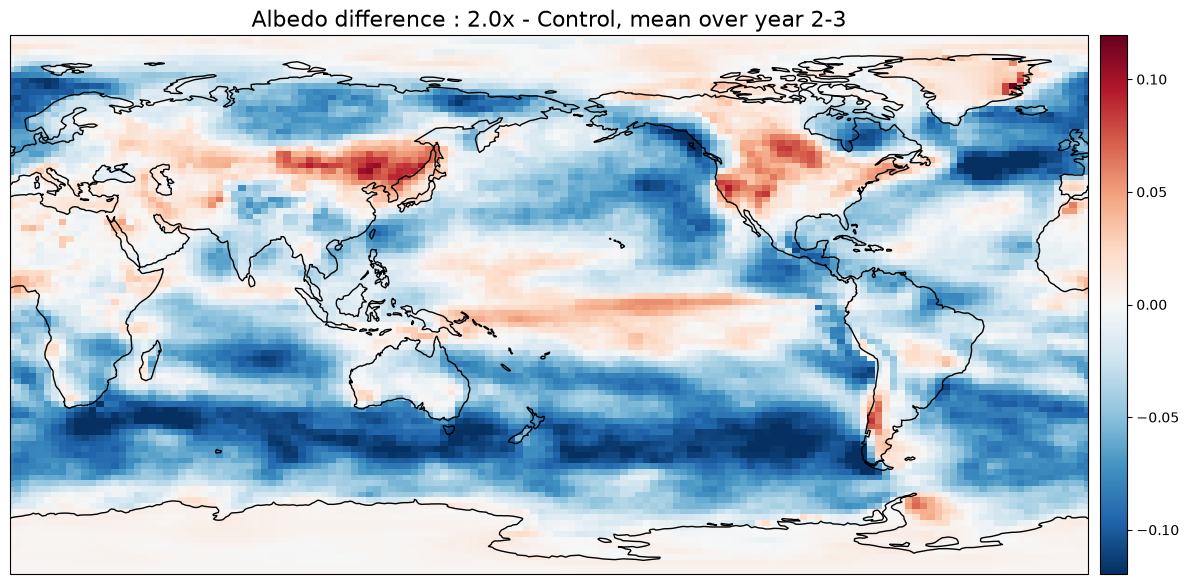

In [25]:
# plotting the difference map between the 2.0x Omega case and the control case
albedo_2p0_diff = albedo_2d_2p0 - albedo_2d_ctl
lim = float(np.abs(albedo_2p0_diff).quantile(0.99))

fig = plt.figure(figsize=(15, 7))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree(central_longitude=180))
img = ax.pcolormesh(albedo_2p0_diff.lon, albedo_2p0_diff.lat, albedo_2p0_diff, cmap="RdBu_r",
                    vmin=-lim, vmax=lim, transform=ccrs.PlateCarree())
ax.coastlines()
plt.colorbar(img, orientation="vertical", fraction=0.0242, pad=0.01)
plt.title(f"Albedo difference : 2.0x - Control, mean over year 2-3", fontsize=16)
plt.show()

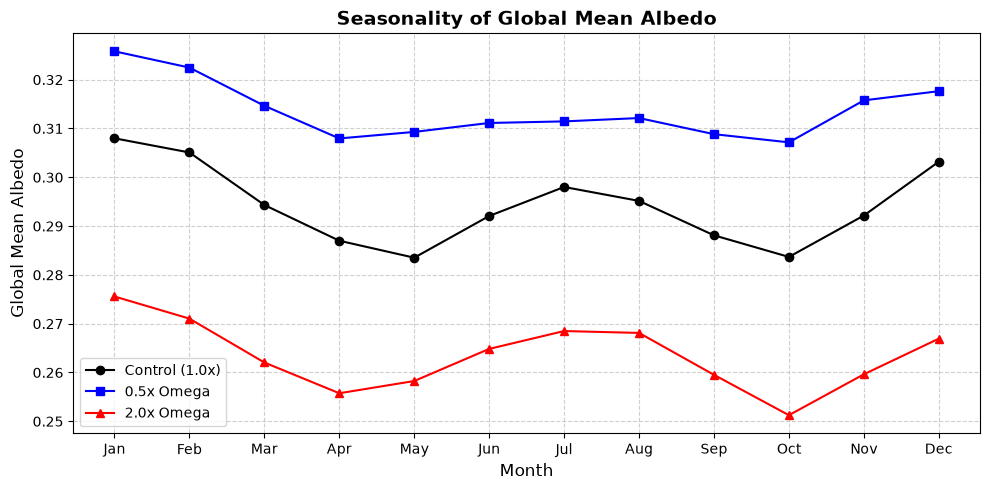

In [40]:
# plotting the seasonal cycle of global mean albedo for each case
# include spinup months to avoid initial transient effects in the analysis
spinup_months = 12


def calc_seasonal_global_albedo(ds, spinup_months=12):
    # Exclude spin-up months
    ds = ds.isel(time=slice(spinup_months, None))

    solin = ds['SOLIN']
    reflected = solin - ds['FSNTOA']

    # Average each flux by calendar month first
    solin_monthly = solin.groupby('time.month').mean(dim='time')
    reflected_monthly = reflected.groupby('time.month').mean(dim='time')

    # Latitude-based area weights
    weights = xr.DataArray(
        np.cos(np.deg2rad(solin_monthly['lat'])),
        dims=['lat'],
        coords={'lat': solin_monthly['lat']},
    )

    incoming_global = solin_monthly.weighted(weights).mean(
        dim=['lat', 'lon']
    )
    reflected_global = reflected_monthly.weighted(weights).mean(
        dim=['lat', 'lon']
    )

    return (reflected_global / incoming_global).where(
        incoming_global > 0
    )


seas_ctl = calc_seasonal_global_albedo(h1, spinup_months)
seas_0p5 = calc_seasonal_global_albedo(h2, spinup_months)
seas_2p0 = calc_seasonal_global_albedo(h3, spinup_months)


plt.figure(figsize=(10, 5))

plt.plot(
    seas_ctl['month'], seas_ctl,
    label='Control (1.0x)', marker='o', color='black'
)
plt.plot(
    seas_0p5['month'], seas_0p5,
    label='0.5x Omega', marker='s', color='blue'
)
plt.plot(
    seas_2p0['month'], seas_2p0,
    label='2.0x Omega', marker='^', color='red'
)

plt.title('Seasonality of Global Mean Albedo',
          fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Global Mean Albedo', fontsize=12)
plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

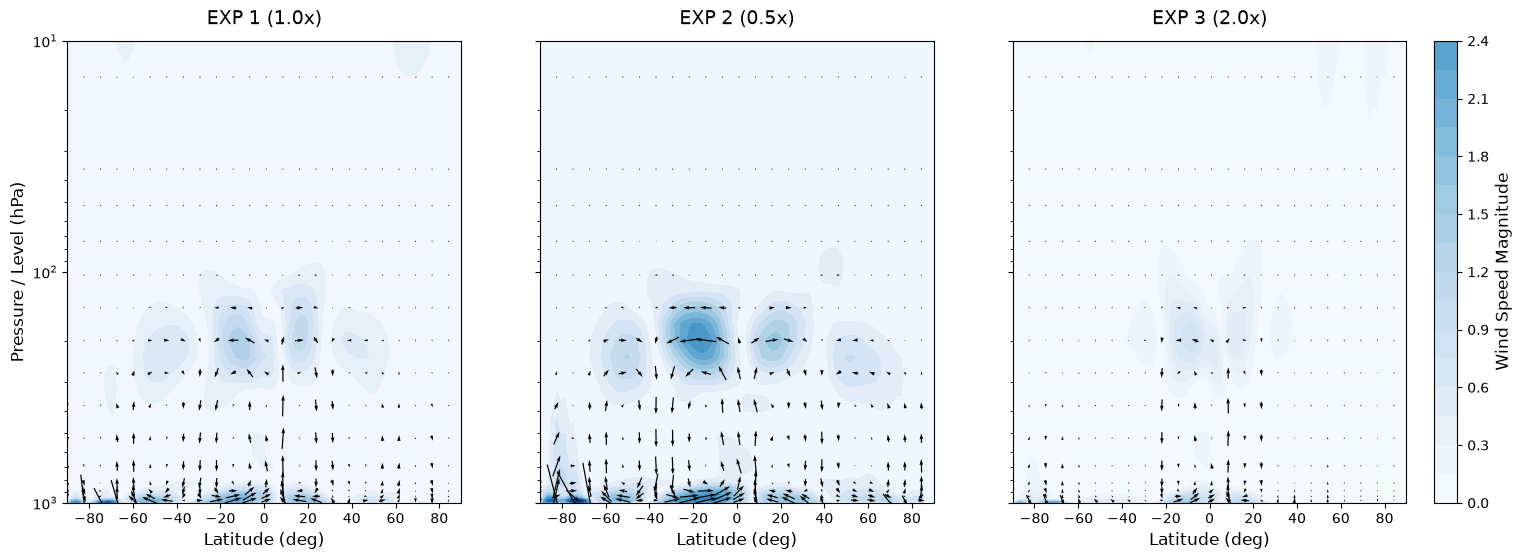

In [27]:
# plotting of zonal mean meridional circulation (V, W) for each case (not included in the report)
def process_circulation_data(ds):
    # include spinup months to avoid initial transient effects in the analysis
    spinup_months = 12
    ds_mean = ds.isel(time=slice(spinup_months, None)).mean(dim='time')
    
    v_var = 'V' if 'V' in ds_mean else 'v'
    w_var = 'OMEGA' if 'OMEGA' in ds_mean else ('W' if 'W' in ds_mean else 'w')
    
    if 'lon' in ds_mean.dims or 'longitude' in ds_mean.dims:
        lon_dim = 'lon' if 'lon' in ds_mean.dims else 'longitude'
        v_data = ds_mean[v_var].mean(dim=lon_dim)
        w_data = ds_mean[w_var].mean(dim=lon_dim)
    else:
        v_data = ds_mean[v_var]
        w_data = ds_mean[w_var]
        
    return v_data, w_data

v0, w0 = process_circulation_data(h1)
v1, w1 = process_circulation_data(h2)
v2, w2 = process_circulation_data(h3)

lat = h2['lat'] if 'lat' in h2 else h2['latitude']
lev = h2['lev'] if 'lev' in h2 else h2['level']
Lat, Lev = np.meshgrid(lat, lev)

speed0 = np.sqrt(v0**2 + w0**2)
speed1 = np.sqrt(v1**2 + w1**2)
speed2 = np.sqrt(v2**2 + w2**2)

v_min = min(speed1.min().values, speed2.min().values)
v_max = max(speed1.max().values, speed2.max().values)

w0_scaled = w0 * -100
w1_scaled = w1 * -100
w2_scaled = w2 * -100

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

experiments = [
    {'ax': axes[0], 'title': 'EXP 1 (1.0x)', 'speed': speed0, 'v': v0, 'w': w0_scaled},
    {'ax': axes[1], 'title': 'EXP 2 (0.5x)', 'speed': speed1, 'v': v1, 'w': w1_scaled},
    {'ax': axes[2], 'title': 'EXP 3 (2.0x)', 'speed': speed2, 'v': v2, 'w': w2_scaled}
]

skip_y = slice(None, None, 2)
skip_x = slice(None, None, 4)

for exp in experiments:
    ax = exp['ax']
    
    c = ax.contourf(Lat, Lev, exp['speed'], levels=15, cmap='Blues', vmin=v_min, vmax=v_max)
    
    ax.quiver(
        Lat[skip_y, skip_x], 
        Lev[skip_y, skip_x], 
        exp['v'].values[skip_y, skip_x], 
        exp['w'].values[skip_y, skip_x],
        color='k', 
        pivot='middle',
        scale=50
    )
    
    ax.set_yscale('log')
    ax.set_title(exp['title'], fontsize=14, pad=12)
    ax.set_xlabel('Latitude (deg)', fontsize=12)

axes[0].set_ylabel('Pressure / Level (hPa)', fontsize=12)
ax.set_ylim(1000, 10)

cbar = fig.colorbar(c, ax=axes, orientation='vertical', fraction=0.02, pad=0.02)
cbar.set_label('Wind Speed Magnitude', fontsize=12)

plt.show()

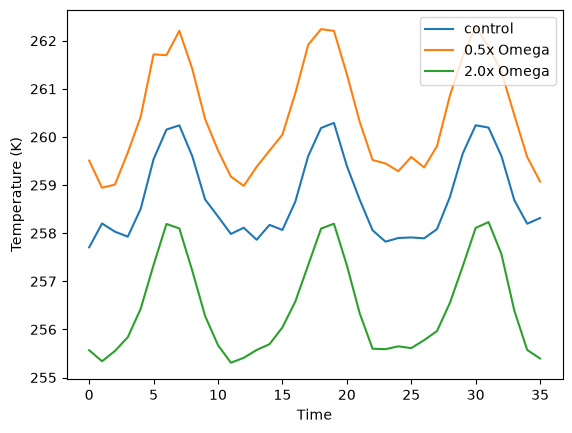

In [28]:
# plotting of global mean temperature time series for each case to see how much I should spin up the model to avoid initial transient effects

def gmean_ts(da):
    w = np.cos(np.deg2rad(da['lat']))
    return da.weighted(w).mean(['lat', 'lon'])


plt.plot(gmean_ts(h1['T'].sel(lev=500, method='nearest')).values, label='control')
plt.plot(gmean_ts(h2['T'].sel(lev=500, method='nearest')).values, label='0.5x Omega')
plt.plot(gmean_ts(h3['T'].sel(lev=500, method='nearest')).values, label='2.0x Omega')

plt.legend() 
plt.xlabel('Time')
plt.ylabel('Temperature (K)')
plt.show()

In [29]:
# calculating the difference in global mean temperature between the first and second year, and between the second and third year for each case 
# to see if the spinup period of 12 months is sufficient to avoid initial transient effects
print("====Control Case====")
t = gmean_ts(h1['T'].sel(lev=500, method='nearest')).values            
d = t[12:24] - t[0:12]               
print("second year - first year:" + str(d.round(2)), d.mean().round(2))
d = t[24:36] - t[12:24]             
print("third year - second year:" + str(d.round(2)), d.mean().round(2))

print("====0.5x Case====")
t = gmean_ts(h2['T'].sel(lev=500, method='nearest')).values            
d = t[12:24] - t[0:12]               
print("second year - first year:" + str(d.round(2)), d.mean().round(2))
d = t[24:36] - t[12:24]              
print("third year - second year:" + str(d.round(2)), d.mean().round(2))

print("====2.0x Case====")
t = gmean_ts(h3['T'].sel(lev=500, method='nearest')).values            
d = t[12:24] - t[0:12]               
print("second year - first year:" + str(d.round(2)), d.mean().round(2))
d = t[24:36] - t[12:24]              
print("third year - second year:" + str(d.round(2)), d.mean().round(2))

====Control Case====
second year - first year:[ 0.41 -0.34  0.14  0.14  0.15  0.06  0.03  0.05 -0.2  -0.   -0.29 -0.16] -0.0
third year - second year:[-0.21  0.05 -0.28  0.02  0.1   0.06  0.06 -0.1   0.2  -0.01  0.14  0.49] 0.04
====0.5x Case====
second year - first year:[-0.53  0.43  0.71  0.37  0.49  0.2   0.54 -0.   -0.11 -0.06 -0.2   0.27] 0.18
third year - second year:[ 0.31  0.2  -0.35 -0.24 -0.05 -0.24  0.05 -0.33  0.04  0.14  0.06 -0.38] -0.06
====2.0x Case====
second year - first year:[-0.16  0.24  0.14  0.2   0.15 -0.   -0.1   0.1   0.11  0.06 -0.07  0.28] 0.08
third year - second year:[ 0.24  0.04  0.08 -0.08 -0.03 -0.02  0.01  0.03  0.23  0.06 -0.02 -0.19] 0.03


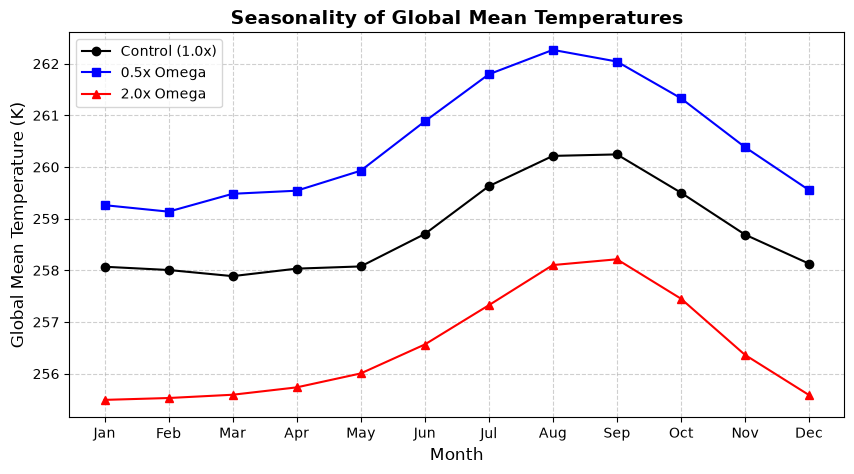

In [30]:
# plotting the seasonal cycle of global mean temperature for each case
# include spinup months to avoid initial transient effects in the analysis
spinup_months = 12

plt.figure(figsize=(10, 5))

temp_ctl = gmean_ts(
    h1['T'].sel(lev=500, method='nearest').isel(time=slice(spinup_months, None))
).groupby('time.month').mean()

temp_0p5 = gmean_ts(
    h2['T'].sel(lev=500, method='nearest').isel(time=slice(spinup_months, None))
).groupby('time.month').mean()

temp_2p0 = gmean_ts(
    h3['T'].sel(lev=500, method='nearest').isel(time=slice(spinup_months, None))
).groupby('time.month').mean()

plt.plot(temp_ctl.month, temp_ctl, label='Control (1.0x)', marker='o', color='black')
plt.plot(temp_0p5.month, temp_0p5, label='0.5x Omega', marker='s', color='blue')
plt.plot(temp_2p0.month, temp_2p0, label='2.0x Omega', marker='^', color='red')

plt.title('Seasonality of Global Mean Temperatures', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Global Mean Temperature (K)', fontsize=12)
plt.xticks(
    range(1, 13),
    [
        'Jan',
        'Feb',
        'Mar',
        'Apr',
        'May',
        'Jun',
        'Jul',
        'Aug',
        'Sep',
        'Oct',
        'Nov',
        'Dec',
    ],
)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

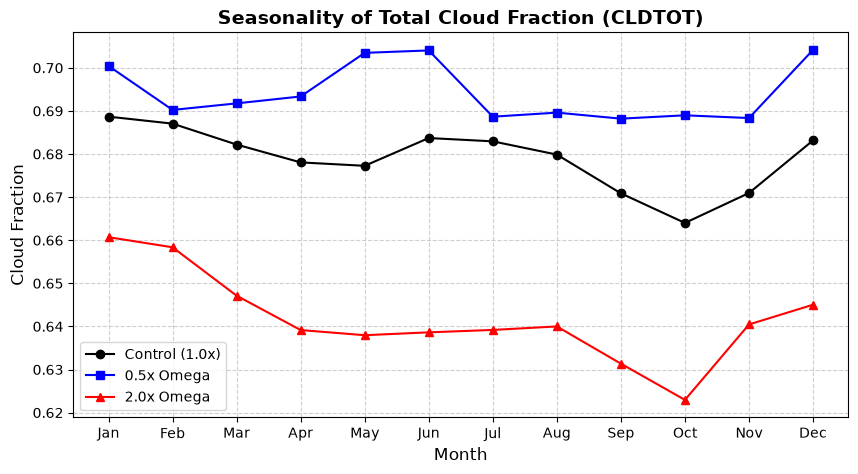

In [ ]:
# plotting the seasonal cycle of total cloud fraction for each case
# include spinup months to avoid initial transient effects in the analysis
spinup_months = 12

plt.figure(figsize=(10, 5))


cld_ctl = gmean_ts(
    h1['CLDTOT'].isel(time=slice(spinup_months, None))
).groupby('time.month').mean()

cld_0p5 = gmean_ts(
    h2['CLDTOT'].isel(time=slice(spinup_months, None))
).groupby('time.month').mean()

cld_2p0 = gmean_ts(
    h3['CLDTOT'].isel(time=slice(spinup_months, None))
).groupby('time.month').mean()

plt.plot(cld_ctl.month, cld_ctl, label='Control (1.0x)', marker='o', color='black')
plt.plot(cld_0p5.month, cld_0p5, label='0.5x Omega', marker='s', color='blue')
plt.plot(cld_2p0.month, cld_2p0, label='2.0x Omega', marker='^', color='red')

plt.title('Seasonality of Total Cloud Fraction (CLDTOT)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Cloud Fraction', fontsize=12)
plt.xticks(
    range(1, 13),
    [
        'Jan',
        'Feb',
        'Mar',
        'Apr',
        'May',
        'Jun',
        'Jul',
        'Aug',
        'Sep',
        'Oct',
        'Nov',
        'Dec',
    ],
)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()
